In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

Selected device: cuda


In [4]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/AI_Image_Project")

print("Project exists:", ROOT.exists())

for path in sorted(ROOT.rglob("*")):
    if any(x in path.parts for x in [
        ".git", "__pycache__", ".ipynb_checkpoints",
        "venv", ".venv"
    ]):
        continue

    if path.is_file():
        print(path.relative_to(ROOT))

Streaming output truncated to the last 5000 lines.
Partial_AI_5000/Original/107094_orig_1024.png
Partial_AI_5000/Original/107226_mask_bbox.png_ps_mask.png_flux1dev_2__107226_orig_1024.png
Partial_AI_5000/Original/107226_orig_1024.png
Partial_AI_5000/Original/108026_mask_bbox.png_ps_mask.png_flux1dev_0__108026_orig.png
Partial_AI_5000/Original/108026_mask_bbox.png_ps_mask.png_flux1dev_1__108026_orig.png
Partial_AI_5000/Original/108026_mask_bbox.png_ps_mask.png_flux1dev_2__108026_orig.png
Partial_AI_5000/Original/108026_mask_segm.png_ps_mask.png_flux1dev_0__108026_orig.png
Partial_AI_5000/Original/108026_mask_segm.png_ps_mask.png_flux1dev_2__108026_orig.png
Partial_AI_5000/Original/108026_orig.png
Partial_AI_5000/Original/109313_mask_bbox.png_ps_mask.png_flux1dev_0__109313_orig.png
Partial_AI_5000/Original/109313_mask_bbox.png_ps_mask.png_flux1dev_2__109313_orig.png
Partial_AI_5000/Original/109313_mask_segm.png_ps_mask.png_flux1dev_0__109313_orig.png
Partial_AI_5000/Original/109313_mask_

Original : True /content/drive/MyDrive/AI_Image_Project/Partial_AI_5000/Original/100428_orig.png
Manipulated : True /content/drive/MyDrive/AI_Image_Project/Partial_AI_5000/Manipulated/100428_mask_segm.png_ps_mask.png_flux1dev_0.png
Mask : True /content/drive/MyDrive/AI_Image_Project/Partial_AI_5000/Masks/100428_mask_segm.png_ps_mask.png_flux1dev_0__100428_mask_segm.png


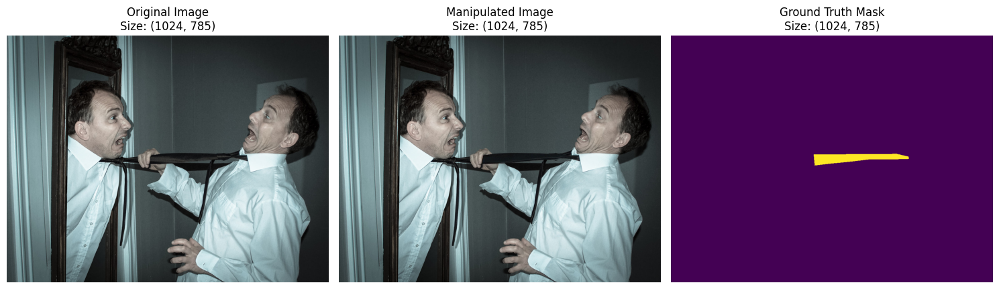

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Dataset folder
BASE_DIR = "/content/drive/MyDrive/AI_Image_Project/Partial_AI_5000"

# Load pairs
pairs = pd.read_csv(os.path.join(BASE_DIR, "pairs.csv"))

# Select one segmentation example
sample = pairs[pairs["mask_type"] == "segm"].iloc[0]

# Construct paths
original_path = os.path.join(BASE_DIR, sample["original_path"])
manipulated_path = os.path.join(BASE_DIR, sample["manipulated_path"])
mask_path = os.path.join(BASE_DIR, sample["mask_path"])

# Check files
for name, path in [
    ("Original", original_path),
    ("Manipulated", manipulated_path),
    ("Mask", mask_path)
]:
    print(name, ":", os.path.exists(path), path)

# Display images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, path, title in zip(
    axes,
    [original_path, manipulated_path, mask_path],
    ["Original Image", "Manipulated Image", "Ground Truth Mask"]
):
    if os.path.exists(path):
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(f"{title}\nSize: {img.size}")
    else:
        ax.set_title(f"{title}\nFILE NOT FOUND")

    ax.axis("off")

plt.tight_layout()
plt.show()

Mask shape: (785, 1024)
Unique mask values: [  0 255]
Minimum: 0
Maximum: 255


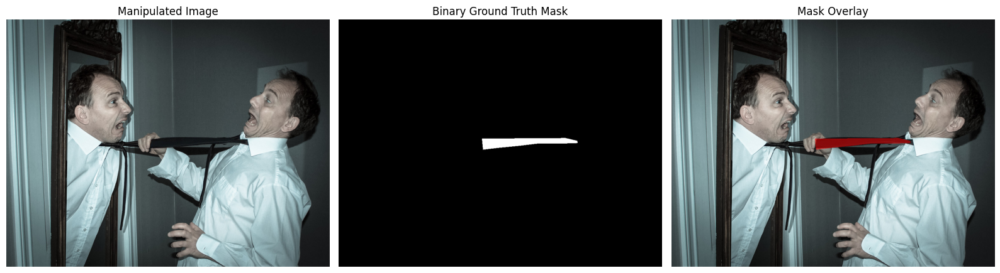

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load images
original = Image.open(original_path).convert("RGB")
manipulated = Image.open(manipulated_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

# Convert to NumPy
original_np = np.array(original)
manipulated_np = np.array(manipulated)
mask_np = np.array(mask)

# Inspect mask values
print("Mask shape:", mask_np.shape)
print("Unique mask values:", np.unique(mask_np)[:30])
print("Minimum:", mask_np.min())
print("Maximum:", mask_np.max())

# Create binary mask
binary_mask = mask_np > 0

# Overlay mask in red
overlay = manipulated_np.copy()
overlay[binary_mask] = (
    0.5 * manipulated_np[binary_mask] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

# Display
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(manipulated_np)
axes[0].set_title("Manipulated Image")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("Binary Ground Truth Mask")

axes[2].imshow(overlay)
axes[2].set_title("Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Calculate manipulated pixel percentage
total_pixels = binary_mask.size
manipulated_pixels = np.count_nonzero(binary_mask)

area_percentage = (
    manipulated_pixels / total_pixels
) * 100

print("Total pixels:", total_pixels)
print("Manipulated pixels:", manipulated_pixels)
print(f"Manipulated area: {area_percentage:.4f}%")

Total pixels: 803840
Manipulated pixels: 6597
Manipulated area: 0.8207%


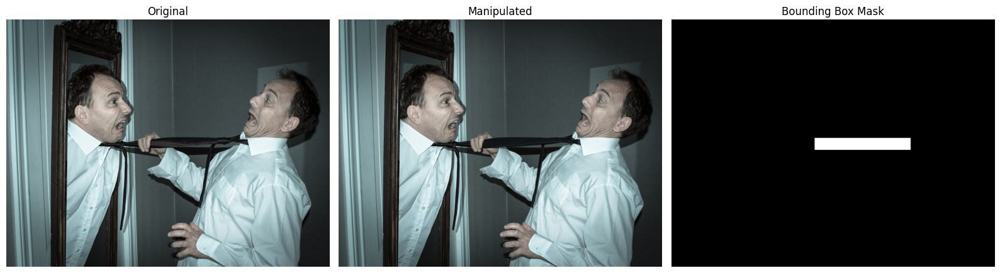

Original: (1024, 785)
Manipulated: (1024, 785)
Mask: (1024, 785)
Mask values: [  0 255]


In [8]:
# Select one bounding-box example
bbox_sample = pairs[pairs["mask_type"] == "bbox"].iloc[0]

bbox_original_path = os.path.join(
    BASE_DIR, bbox_sample["original_path"]
)

bbox_manipulated_path = os.path.join(
    BASE_DIR, bbox_sample["manipulated_path"]
)

bbox_mask_path = os.path.join(
    BASE_DIR, bbox_sample["mask_path"]
)

# Load images
bbox_original = Image.open(bbox_original_path).convert("RGB")
bbox_manipulated = Image.open(bbox_manipulated_path).convert("RGB")
bbox_mask = Image.open(bbox_mask_path).convert("L")

# Display
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(bbox_original)
axes[0].set_title("Original")

axes[1].imshow(bbox_manipulated)
axes[1].set_title("Manipulated")

axes[2].imshow(bbox_mask, cmap="gray")
axes[2].set_title("Bounding Box Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original:", bbox_original.size)
print("Manipulated:", bbox_manipulated.size)
print("Mask:", bbox_mask.size)
print("Mask values:", np.unique(np.array(bbox_mask))[:30])

In [9]:
import os
import pandas as pd
import numpy as np
from PIL import Image

# Use the same BASE_DIR from our previous notebook
pairs = pd.read_csv(os.path.join(BASE_DIR, "pairs.csv"))

# Keep segmentation annotations only
segm_df = pairs[pairs["mask_type"] == "segm"].copy()

print("Total pairs:", len(pairs))
print("Segmentation samples:", len(segm_df))
print("Unique source images:", segm_df["source_id"].nunique())

# Check file availability
def check_file(path):
    return os.path.exists(os.path.join(BASE_DIR, path))

for column in ["original_path", "manipulated_path", "mask_path"]:
    segm_df[column + "_exists"] = segm_df[column].apply(check_file)

    print(
        column,
        "available:",
        segm_df[column + "_exists"].sum(),
        "/",
        len(segm_df)
    )

# Display first few records
display(
    segm_df[
        ["source_id", "original_path",
         "manipulated_path", "mask_path"]
    ].head()
)

Total pairs: 5000
Segmentation samples: 2487
Unique source images: 1121
original_path available: 2487 / 2487
manipulated_path available: 2487 / 2487
mask_path available: 2487 / 2487


,source_id,original_path,manipulated_path,mask_path
3,100428,Original/100428_orig.png,Manipulated/100428_mask_segm.png_ps_mask.png_f...,Masks/100428_mask_segm.png_ps_mask.png_flux1de...
4,100428,Original/100428_orig.png,Manipulated/100428_mask_segm.png_ps_mask.png_f...,Masks/100428_mask_segm.png_ps_mask.png_flux1de...
5,100428,Original/100428_orig.png,Manipulated/100428_mask_segm.png_ps_mask.png_f...,Masks/100428_mask_segm.png_ps_mask.png_flux1de...
6,100489,Original/100489_orig_1024.png,Manipulated/100489_mask_segm.png_ps_mask.png_f...,Masks/100489_mask_segm.png
10,100624,Original/100624_orig.png,Manipulated/100624_mask_segm.png_ps_mask.png_f...,Masks/100624_mask_segm.png_ps_mask.png_flux1de...


In [10]:
import os
import numpy as np
import pandas as pd
import torch

# Project directories
FEATURES_DIR = os.path.join(BASE_DIR, "features")
SAVED_MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

# Localization directories
LOC_FEATURES_DIR = os.path.join(FEATURES_DIR, "localization")
LOC_MODELS_DIR = os.path.join(SAVED_MODELS_DIR, "localization")
LOC_RESULTS_DIR = os.path.join(RESULTS_DIR, "localization")

for folder in [
    LOC_FEATURES_DIR,
    LOC_MODELS_DIR,
    LOC_RESULTS_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Localization directories created!")

Localization directories created!


In [11]:
import os

# BASE_DIR points to Partial_AI_5000
PROJECT_DIR = os.path.dirname(BASE_DIR.rstrip("/"))

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("\nExisting folders and files:\n")

for item in sorted(os.listdir(PROJECT_DIR)):
    path = os.path.join(PROJECT_DIR, item)

    if os.path.isdir(path):
        print(f"📁 {item}/")

        for subitem in sorted(os.listdir(path))[:15]:
            subpath = os.path.join(path, subitem)
            prefix = "📁" if os.path.isdir(subpath) else "📄"
            print(f"    {prefix} {subitem}")

    else:
        print(f"📄 {item}")

PROJECT DIRECTORY: /content/drive/MyDrive/AI_Image_Project

Existing folders and files:

📁 COCO_5000/
    📄 000000000139.jpg
    📄 000000000285.jpg
    📄 000000000632.jpg
    📄 000000000724.jpg
    📄 000000000776.jpg
    📄 000000000785.jpg
    📄 000000000802.jpg
    📄 000000000872.jpg
    📄 000000000885.jpg
    📄 000000001000.jpg
    📄 000000001268.jpg
    📄 000000001296.jpg
    📄 000000001353.jpg
    📄 000000001425.jpg
    📄 000000001490.jpg
📁 DiffusionDB_5000/
    📄 000b7b74-0a22-4d0c-b717-e240fdc5d555.png
    📄 001326ce-6729-413b-9479-a0d2b3f489ce.png
    📄 003b5d37-172b-4b46-9b91-1d78d4eb200e.png
    📄 0049a37b-76a2-49bf-9075-adb497a74266.png
    📄 005b7bbb-06da-46e6-8a80-82e9e01ebfca.png
    📄 007d6097-ed1b-4183-af99-f7dff5eae967.png
    📄 00801197-b76a-4f2b-ba3c-867d8b9e3644.png
    📄 008a493e-9801-4ffc-a2ec-823256a32aa4.png
    📄 0097313f-d244-4aee-b38b-b10a3208af99.png
    📄 00bcecb5-8dc8-448c-af0f-3d3ec862a6a4.png
    📄 00d83a64-a624-4ef2-a9b0-2666cde02218.png
    📄 00db43c5-9

In [12]:
import os
import numpy as np
import pandas as pd
from PIL import Image

# Project paths
PROJECT_DIR = "/content/drive/MyDrive/AI_Image_Project"

BASE_DIR = os.path.join(PROJECT_DIR, "Partial_AI_5000")

FEATURES_DIR = os.path.join(PROJECT_DIR, "features")
SAVED_MODELS_DIR = os.path.join(PROJECT_DIR, "saved_models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

# Localization-specific directories
LOC_FEATURES_DIR = os.path.join(FEATURES_DIR, "localization")
LOC_MODELS_DIR = os.path.join(SAVED_MODELS_DIR, "localization")
LOC_RESULTS_DIR = os.path.join(RESULTS_DIR, "localization")

for folder in [LOC_FEATURES_DIR, LOC_MODELS_DIR, LOC_RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

# Load CSV
pairs = pd.read_csv(os.path.join(BASE_DIR, "pairs.csv"))

# Keep segmentation samples
segm_df = pairs[pairs["mask_type"] == "segm"].copy()
segm_df = segm_df.reset_index(drop=True)

print("Segmentation samples:", len(segm_df))
print("Unique source images:", segm_df["source_id"].nunique())
print("Localization directories ready!")

Segmentation samples: 2487
Unique source images: 1121
Localization directories ready!


In [13]:
# Convert relative paths into absolute paths
manipulated_paths = np.array([
    os.path.join(BASE_DIR, p)
    for p in segm_df["manipulated_path"]
])

mask_paths = np.array([
    os.path.join(BASE_DIR, p)
    for p in segm_df["mask_path"]
])

original_paths = np.array([
    os.path.join(BASE_DIR, p)
    for p in segm_df["original_path"]
])

source_ids = segm_df["source_id"].to_numpy()

# Verify paths
assert all(os.path.exists(p) for p in manipulated_paths)
assert all(os.path.exists(p) for p in mask_paths)
assert all(os.path.exists(p) for p in original_paths)

# Save metadata
np.save(
    os.path.join(LOC_FEATURES_DIR, "manipulated_image_paths.npy"),
    manipulated_paths
)

np.save(
    os.path.join(LOC_FEATURES_DIR, "segmentation_mask_paths.npy"),
    mask_paths
)

np.save(
    os.path.join(LOC_FEATURES_DIR, "original_image_paths.npy"),
    original_paths
)

np.save(
    os.path.join(LOC_FEATURES_DIR, "source_ids.npy"),
    source_ids
)

print("All metadata saved successfully!")

print("Manipulated paths:", manipulated_paths.shape)
print("Mask paths:", mask_paths.shape)
print("Original paths:", original_paths.shape)
print("Source IDs:", source_ids.shape)

All metadata saved successfully!
Manipulated paths: (2487,)
Mask paths: (2487,)
Original paths: (2487,)
Source IDs: (2487,)


In [14]:
from tqdm.auto import tqdm

area_percentages = []

for mask_path in tqdm(mask_paths, desc="Processing masks"):

    mask = np.array(
        Image.open(mask_path).convert("L")
    )

    binary_mask = mask > 0

    area = (
        np.count_nonzero(binary_mask) /
        binary_mask.size
    ) * 100

    area_percentages.append(area)

area_percentages = np.array(
    area_percentages,
    dtype=np.float32
)

np.save(
    os.path.join(
        LOC_FEATURES_DIR,
        "ground_truth_area_percentages.npy"
    ),
    area_percentages
)

print("Ground-truth area percentages saved!")
print("Minimum:", area_percentages.min())
print("Maximum:", area_percentages.max())
print("Mean:", area_percentages.mean())
print("Median:", np.median(area_percentages))

Processing masks:   0%|          | 0/2487 [00:00<?, ?it/s]

Exception ignored in: <generator object tqdm_notebook.__iter__ at 0x7a3e4cfd6960>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tqdm/notebook.py", line 250, in __iter__
    yield from it
  File "/usr/local/lib/python3.13/dist-packages/tqdm/std.py", line 1196, in __iter__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/tqdm/notebook.py", line 270, in close
    def close(self):
KeyboardInterrupt: 


KeyboardInterrupt: 

In [15]:
print("Saved localization files:\n")

for filename in sorted(os.listdir(LOC_FEATURES_DIR)):
    path = os.path.join(LOC_FEATURES_DIR, filename)

    data = np.load(path, allow_pickle=True)

    print(filename, "| Shape:", data.shape, "| Type:", data.dtype)

Saved localization files:

ground_truth_area_percentages.npy | Shape: (2487,) | Type: float32
manipulated_image_paths.npy | Shape: (2487,) | Type: <U115
original_image_paths.npy | Shape: (2487,) | Type: <U85
segmentation_mask_paths.npy | Shape: (2487,) | Type: <U127
source_ids.npy | Shape: (2487,) | Type: int64
test_idx.npy | Shape: (239,) | Type: int64
train_idx.npy | Shape: (1983,) | Type: int64
val_idx.npy | Shape: (265,) | Type: int64


In [16]:
from sklearn.model_selection import GroupShuffleSplit

# Group identifier for every sample
groups = source_ids

# First split: 80% training, 20% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(manipulated_paths, groups=groups)
)

# Second split: divide temporary into 10% validation and 10% test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative_idx, test_relative_idx = next(
    split2.split(
        manipulated_paths[temp_idx],
        groups=groups[temp_idx]
    )
)

val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))

print("\nUnique source IDs:")
print("Train:", len(np.unique(source_ids[train_idx])))
print("Validation:", len(np.unique(source_ids[val_idx])))
print("Test:", len(np.unique(source_ids[test_idx])))

Train samples: 1983
Validation samples: 265
Test samples: 239

Unique source IDs:
Train: 896
Validation: 112
Test: 113


In [17]:
train_sources = set(source_ids[train_idx])
val_sources = set(source_ids[val_idx])
test_sources = set(source_ids[test_idx])

print("Train ∩ Validation:", len(train_sources & val_sources))
print("Train ∩ Test:", len(train_sources & test_sources))
print("Validation ∩ Test:", len(val_sources & test_sources))

assert len(train_sources & val_sources) == 0
assert len(train_sources & test_sources) == 0
assert len(val_sources & test_sources) == 0

print("\nSUCCESS: No source-image leakage!")

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

SUCCESS: No source-image leakage!


In [18]:
np.save(os.path.join(LOC_FEATURES_DIR, "train_idx.npy"), train_idx)
np.save(os.path.join(LOC_FEATURES_DIR, "val_idx.npy"), val_idx)
np.save(os.path.join(LOC_FEATURES_DIR, "test_idx.npy"), test_idx)

print("All split indices saved successfully!")

All split indices saved successfully!


In [19]:
for filename in sorted(os.listdir(LOC_FEATURES_DIR)):
    path = os.path.join(LOC_FEATURES_DIR, filename)

    data = np.load(path, allow_pickle=True)

    print(f"{filename:45s} Shape: {data.shape}")

ground_truth_area_percentages.npy             Shape: (2487,)
manipulated_image_paths.npy                   Shape: (2487,)
original_image_paths.npy                      Shape: (2487,)
segmentation_mask_paths.npy                   Shape: (2487,)
source_ids.npy                                Shape: (2487,)
test_idx.npy                                  Shape: (239,)
train_idx.npy                                 Shape: (1983,)
val_idx.npy                                   Shape: (265,)


In [20]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)


class LocalizationDataset(Dataset):

    def __init__(self, image_paths, mask_paths, indices,
                 image_size=256):

        self.image_paths = image_paths[indices]
        self.mask_paths = mask_paths[indices]
        self.image_size = image_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        # Load image and mask
        image = Image.open(
            self.image_paths[idx]
        ).convert("RGB")

        mask = Image.open(
            self.mask_paths[idx]
        ).convert("L")

        # Preserve aspect ratio
        w, h = image.size

        scale = min(
            self.image_size / w,
            self.image_size / h
        )

        new_w = round(w * scale)
        new_h = round(h * scale)

        image = image.resize(
            (new_w, new_h),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (new_w, new_h),
            Image.Resampling.NEAREST
        )

        # Create padded canvases
        image_canvas = Image.new(
            "RGB",
            (self.image_size, self.image_size),
            (0, 0, 0)
        )

        mask_canvas = Image.new(
            "L",
            (self.image_size, self.image_size),
            0
        )

        x_offset = (self.image_size - new_w) // 2
        y_offset = (self.image_size - new_h) // 2

        image_canvas.paste(
            image, (x_offset, y_offset)
        )

        mask_canvas.paste(
            mask, (x_offset, y_offset)
        )

        # Convert to tensors
        image_array = np.array(
            image_canvas, dtype=np.float32
        ) / 255.0

        mask_array = (
            np.array(mask_canvas) > 0
        ).astype(np.float32)

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1)
        )

        mask_tensor = torch.from_numpy(
            mask_array
        ).unsqueeze(0)

        return image_tensor, mask_tensor

Selected device: cuda


In [31]:
BATCH_SIZE = 4

train_dataset = LocalizationDataset(
    manipulated_paths, mask_paths, train_idx
)

val_dataset = LocalizationDataset(
    manipulated_paths, mask_paths, val_idx
)

test_dataset = LocalizationDataset(
    manipulated_paths, mask_paths, test_idx
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 496
Validation batches: 67
Test batches: 60


In [32]:
images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image range:", images.min().item(),
      images.max().item())

print("Mask values:", torch.unique(masks))

Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])
Image range: 0.0 1.0
Mask values: tensor([0., 1.])


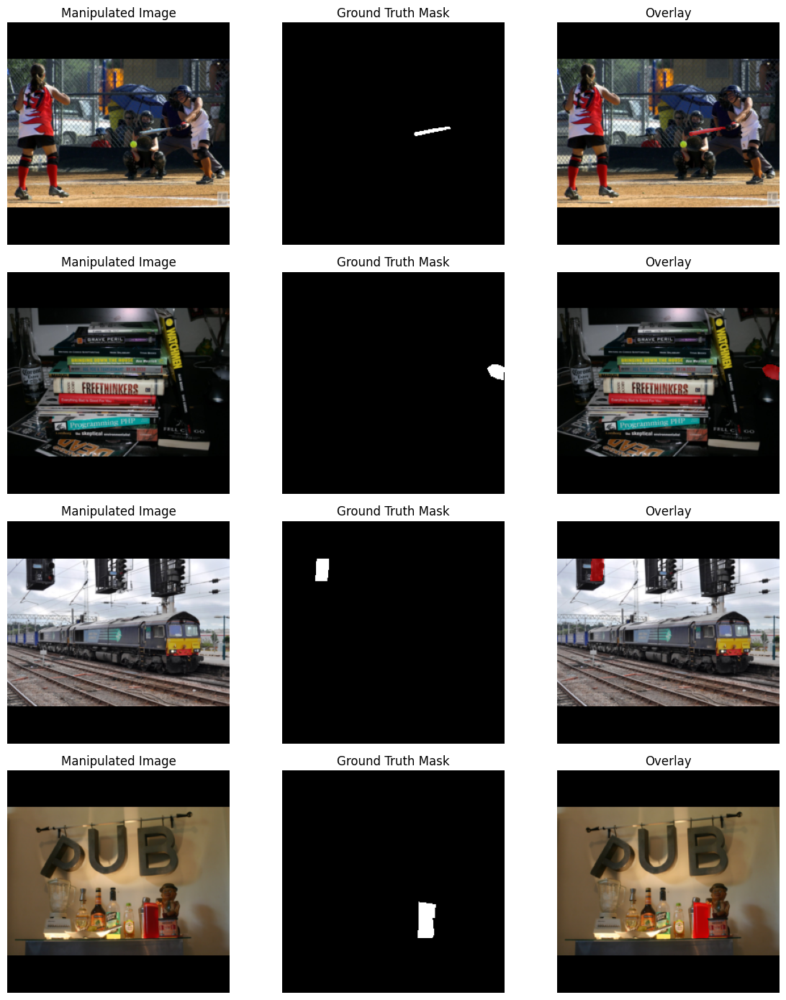

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for i in range(4):

    image = images[i].permute(1, 2, 0).numpy()
    mask = masks[i, 0].numpy()

    overlay = image.copy()
    overlay[mask > 0] = (
        0.5 * image[mask > 0] +
        0.5 * np.array([1, 0, 0])
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Manipulated Image")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(kernel_size=2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        # One output channel: manipulated-region probability logits
        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with skip connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


model = UNet().to(device)

print("U-Net created successfully!")
print("Device:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))


U-Net created successfully!
Device: cuda
Total parameters: 7765985


In [25]:

with torch.no_grad():
    sample_images, sample_masks = next(iter(train_loader))
    sample_images = sample_images.to(device)

    predictions = model(sample_images)

print("Input shape:", sample_images.shape)
print("Ground truth shape:", sample_masks.shape)
print("Predicted output shape:", predictions.shape)


Input shape: torch.Size([4, 3, 256, 256])
Ground truth shape: torch.Size([4, 1, 256, 256])
Predicted output shape: torch.Size([4, 1, 256, 256])


In [26]:

class CombinedLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, predictions, targets):
        # Binary Cross-Entropy
        bce_loss = self.bce(predictions, targets)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(predictions)

        # Calculate Dice score
        probabilities = probabilities.flatten(start_dim=1)
        targets = targets.flatten(start_dim=1)

        intersection = (probabilities * targets).sum(dim=1)

        dice_score = (
            (2.0 * intersection + 1e-6) /
            (probabilities.sum(dim=1) + targets.sum(dim=1) + 1e-6)
        )

        dice_loss = 1.0 - dice_score.mean()

        # Combined loss
        total_loss = bce_loss + dice_loss

        return total_loss


criterion = CombinedLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Combined loss function created!")
print("Optimizer: Adam")
print("Learning rate: 0.0001")


Combined loss function created!
Optimizer: Adam
Learning rate: 0.0001


In [29]:

model.train()

images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

optimizer.zero_grad()

predictions = model(images)
loss = criterion(predictions, masks)

print("Loss:", loss.item())
print("Is loss finite:", torch.isfinite(loss).item())


Loss: 1.687056303024292
Is loss finite: True


In [34]:

import os
import numpy as np
from PIL import Image

CACHE_DIR = "/content/localization_cache_128"
os.makedirs(CACHE_DIR, exist_ok=True)

IMAGE_CACHE_PATH = os.path.join(CACHE_DIR, "images.npy")
MASK_CACHE_PATH = os.path.join(CACHE_DIR, "masks.npy")

SIZE = 128
N = len(manipulated_paths)

if not (
    os.path.exists(IMAGE_CACHE_PATH)
    and os.path.exists(MASK_CACHE_PATH)
):

    print("Creating image cache...")

    images_cache = np.zeros((N, SIZE, SIZE, 3), dtype=np.uint8)
    masks_cache = np.zeros((N, SIZE, SIZE), dtype=np.uint8)

    for i in range(N):
        image = Image.open(manipulated_paths[i]).convert("RGB")
        mask = Image.open(mask_paths[i]).convert("L")

        w, h = image.size
        scale = min(SIZE / w, SIZE / h)

        new_w = max(1, int(w * scale))
        new_h = max(1, int(h * scale))

        image = image.resize((new_w, new_h), Image.Resampling.BILINEAR)
        mask = mask.resize((new_w, new_h), Image.Resampling.NEAREST)

        x = (SIZE - new_w) // 2
        y = (SIZE - new_h) // 2

        image_canvas = Image.new("RGB", (SIZE, SIZE), (0, 0, 0))
        mask_canvas = Image.new("L", (SIZE, SIZE), 0)

        image_canvas.paste(image, (x, y))
        mask_canvas.paste(mask, (x, y))

        images_cache[i] = np.asarray(image_canvas)
        masks_cache[i] = (
            np.asarray(mask_canvas) > 0
        ).astype(np.uint8)

        if (i + 1) % 250 == 0:
            print(f"Processed {i+1}/{N}")

    np.save(IMAGE_CACHE_PATH, images_cache)
    np.save(MASK_CACHE_PATH, masks_cache)

    print("Both cache files saved!")

    del images_cache, masks_cache

else:
    print("Both cache files already exist!")

print("Images:", os.path.exists(IMAGE_CACHE_PATH))
print("Masks:", os.path.exists(MASK_CACHE_PATH))


Creating image cache...
Processed 250/2487
Processed 500/2487
Processed 750/2487
Processed 1000/2487
Processed 1250/2487
Processed 1500/2487
Processed 1750/2487
Processed 2000/2487
Processed 2250/2487
Both cache files saved!
Images: True
Masks: True


In [35]:
images_cache = np.load(IMAGE_CACHE_PATH, mmap_mode="r")
masks_cache = np.load(MASK_CACHE_PATH, mmap_mode="r")

print("Image cache shape:", images_cache.shape)
print("Mask cache shape:", masks_cache.shape)

Image cache shape: (2487, 128, 128, 3)
Mask cache shape: (2487, 128, 128)


In [36]:

import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.enc4 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.up4 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec4 = DoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, 2)
        self.dec1 = DoubleConv(32, 16)

        self.output = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))

        return self.output(d1)


model = SmallUNet().to(device)

print("Lightweight U-Net created!")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Device:", device)


Lightweight U-Net created!
Parameters: 1944049
Device: cuda


In [37]:

criterion = CombinedLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

EPOCHS = 5

best_val_dice = -1

best_model_path = os.path.join(
    LOC_MODELS_DIR, "unet_small_128_best.pth"
)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}

def calculate_metrics(predictions, targets):
    predicted = (torch.sigmoid(predictions) > 0.5).float()

    predicted = predicted.flatten(1)
    targets = targets.flatten(1)

    intersection = (predicted * targets).sum(1)
    pred_sum = predicted.sum(1)
    target_sum = targets.sum(1)

    dice = (2 * intersection + 1e-6) / (
        pred_sum + target_sum + 1e-6
    )

    union = pred_sum + target_sum - intersection
    iou = (intersection + 1e-6) / (union + 1e-6)

    return dice.mean().item(), iou.mean().item()


for epoch in range(EPOCHS):

    model.train()
    train_total = 0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, masks)

        loss.backward()
        optimizer.step()

        train_total += loss.item()

    avg_train = train_total / len(train_loader)

    model.eval()
    val_total = 0
    dice_total = 0
    iou_total = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            predictions = model(images)
            loss = criterion(predictions, masks)

            dice, iou = calculate_metrics(predictions, masks)

            val_total += loss.item()
            dice_total += dice
            iou_total += iou

    avg_val = val_total / len(val_loader)
    avg_dice = dice_total / len(val_loader)
    avg_iou = iou_total / len(val_loader)

    history["train_loss"].append(avg_train)
    history["val_loss"].append(avg_val)
    history["val_dice"].append(avg_dice)
    history["val_iou"].append(avg_iou)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Training Loss: {avg_train:.4f}")
    print(f"Validation Loss: {avg_val:.4f}")
    print(f"Validation Dice: {avg_dice:.4f}")
    print(f"Validation IoU: {avg_iou:.4f}")

    if avg_dice > best_val_dice:
        best_val_dice = avg_dice

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": best_val_dice
        }, best_model_path)

        print("Best optimized model saved!")

np.save(
    os.path.join(LOC_RESULTS_DIR, "small_unet_history.npy"),
    history
)

print("\nOptimized training completed!")



Epoch 1/5
Training Loss: 1.5123
Validation Loss: 1.4291
Validation Dice: 0.0038
Validation IoU: 0.0021
Best optimized model saved!

Epoch 2/5
Training Loss: 1.3668
Validation Loss: 1.3797
Validation Dice: 0.0210
Validation IoU: 0.0138
Best optimized model saved!

Epoch 3/5
Training Loss: 1.2746
Validation Loss: 1.2436
Validation Dice: 0.0081
Validation IoU: 0.0048

Epoch 4/5
Training Loss: 1.2050
Validation Loss: 1.1906
Validation Dice: 0.0157
Validation IoU: 0.0096

Epoch 5/5
Training Loss: 1.1523
Validation Loss: 1.1373
Validation Dice: 0.0000
Validation IoU: 0.0000

Optimized training completed!


In [38]:

checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["val_dice"])

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

results = {t: {"intersection": 0, "pred": 0, "gt": 0}
           for t in thresholds}

prob_min = 1.0
prob_max = 0.0
prob_sum = 0.0
total_pixels = 0
total_gt_pixels = 0

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)

        probabilities = torch.sigmoid(model(images)).cpu()

        prob_min = min(prob_min, probabilities.min().item())
        prob_max = max(prob_max, probabilities.max().item())
        prob_sum += probabilities.sum().item()
        total_pixels += probabilities.numel()
        total_gt_pixels += masks.sum().item()

        for t in thresholds:
            predictions = (probabilities > t).float()

            results[t]["intersection"] += (
                predictions * masks
            ).sum().item()

            results[t]["pred"] += predictions.sum().item()
            results[t]["gt"] += masks.sum().item()

print("\nProbability statistics")
print("Minimum:", prob_min)
print("Maximum:", prob_max)
print("Mean:", prob_sum / total_pixels)

print("\nGround truth positive pixels:", int(total_gt_pixels))
print("\nThreshold comparison")

for t in thresholds:
    r = results[t]

    dice = (
        2 * r["intersection"] + 1e-6
    ) / (
        r["pred"] + r["gt"] + 1e-6
    )

    iou = (
        r["intersection"] + 1e-6
    ) / (
        r["pred"] + r["gt"] - r["intersection"] + 1e-6
    )

    print(
        f"Threshold {t}: "
        f"Predicted pixels={int(r['pred'])}, "
        f"Dice={dice:.4f}, IoU={iou:.4f}"
    )


Loaded best epoch: 2
Best validation Dice: 0.021047372539831754

Probability statistics
Minimum: 5.749884803663008e-05
Maximum: 1.0
Mean: 0.2995725108767455

Ground truth positive pixels: 438626

Threshold comparison
Threshold 0.1: Predicted pixels=17365842, Dice=0.0493, IoU=0.0253
Threshold 0.2: Predicted pixels=17360796, Dice=0.0493, IoU=0.0253
Threshold 0.3: Predicted pixels=6264853, Dice=0.0835, IoU=0.0436
Threshold 0.4: Predicted pixels=491402, Dice=0.1099, IoU=0.0581
Threshold 0.5: Predicted pixels=134654, Dice=0.0578, IoU=0.0298


Images shape: (2487, 128, 128, 3)
Masks shape: (2487, 128, 128)

Mask values: [0 1]

Mask area statistics after resizing
Minimum area %: 0.08544921875
Maximum area %: 28.729248046875
Mean area %: 2.871810857867159
Median area %: 1.556396484375
Images with empty masks: 0


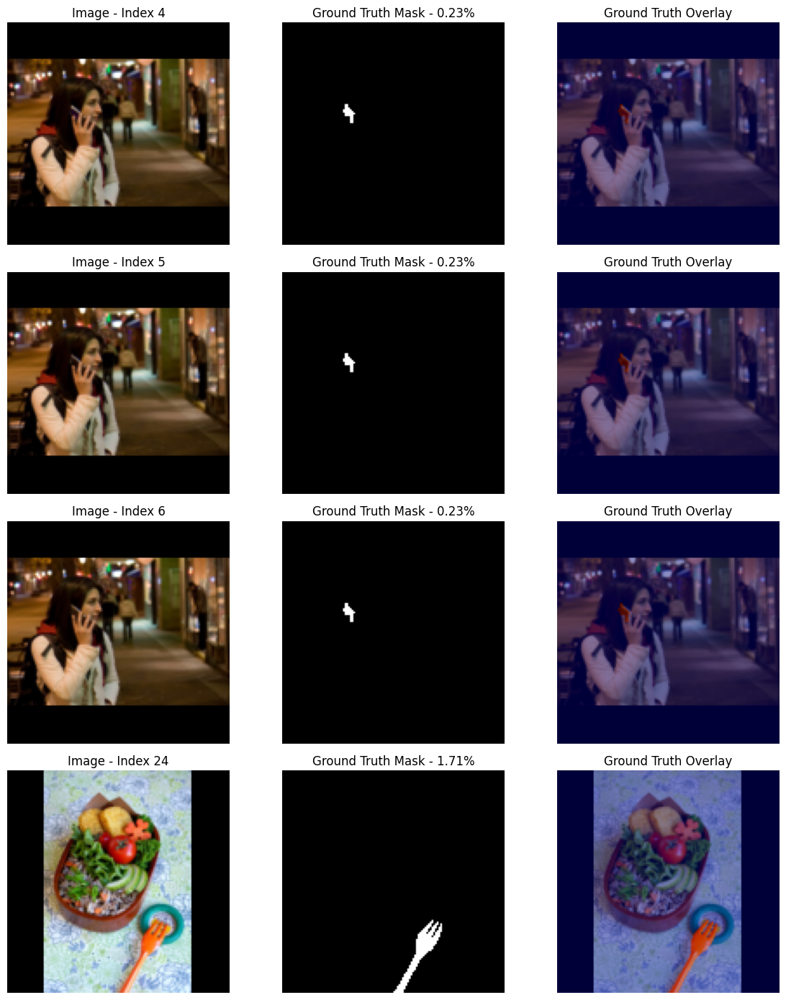

In [39]:

import numpy as np
import matplotlib.pyplot as plt
import os

# Load cached arrays
cached_images = np.load(
    "/content/localization_cache_128/images.npy",
    mmap_mode="r"
)

cached_masks = np.load(
    "/content/localization_cache_128/masks.npy",
    mmap_mode="r"
)

print("Images shape:", cached_images.shape)
print("Masks shape:", cached_masks.shape)

# Check mask values and overall statistics
print("\nMask values:", np.unique(cached_masks[:20]))

mask_areas = []
for i in range(len(cached_masks)):
    positive_pixels = np.count_nonzero(cached_masks[i])
    mask_areas.append(
        positive_pixels / (128 * 128) * 100
    )

mask_areas = np.array(mask_areas)

print("\nMask area statistics after resizing")
print("Minimum area %:", mask_areas.min())
print("Maximum area %:", mask_areas.max())
print("Mean area %:", mask_areas.mean())
print("Median area %:", np.median(mask_areas))
print("Images with empty masks:", np.sum(mask_areas == 0))

# Visualize some validation samples
sample_indices = val_idx[:4]

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row, idx in enumerate(sample_indices):
    image = cached_images[idx]
    mask = cached_masks[idx]

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Image - Index {idx}")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(
        f"Ground Truth Mask - {mask_areas[idx]:.2f}%"
    )

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(mask, cmap="jet", alpha=0.45)
    axes[row, 2].set_title("Ground Truth Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


Image 1: GT pixels = 146, Predicted pixels = 270
Image 2: GT pixels = 146, Predicted pixels = 267
Image 3: GT pixels = 146, Predicted pixels = 268
Image 4: GT pixels = 1128, Predicted pixels = 4252


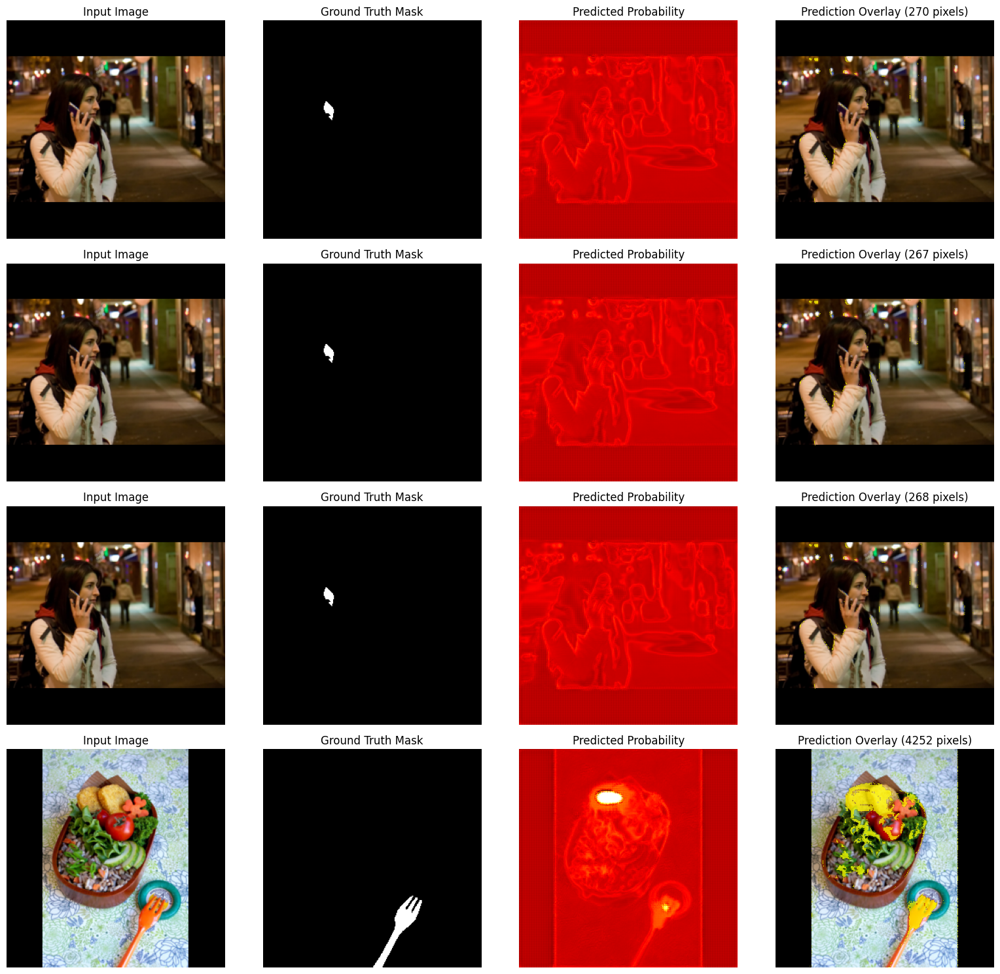

In [40]:

import torch
import numpy as np
import matplotlib.pyplot as plt

# Load the best checkpoint
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Get one validation batch
images, masks = next(iter(val_loader))

with torch.no_grad():
    images_device = images.to(device)
    probabilities = torch.sigmoid(model(images_device)).cpu().numpy()

images = images.cpu().numpy()
masks = masks.cpu().numpy()

threshold = 0.4

fig, axes = plt.subplots(4, 4, figsize=(16, 15))

for i in range(min(4, len(images))):
    image = np.transpose(images[i], (1, 2, 0))
    gt_mask = masks[i, 0]
    pred_prob = probabilities[i, 0]
    pred_mask = (pred_prob >= threshold).astype(np.uint8)

    # Image
    axes[i, 0].imshow(np.clip(image, 0, 1))
    axes[i, 0].set_title("Input Image")

    # Ground truth
    axes[i, 1].imshow(gt_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth Mask")

    # Predicted probability map
    axes[i, 2].imshow(pred_prob, cmap="hot", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted Probability")

    # Correctly display only positive predicted pixels
    axes[i, 3].imshow(np.clip(image, 0, 1))
    visible_mask = np.ma.masked_where(pred_mask == 0, pred_mask)
    axes[i, 3].imshow(
        visible_mask, cmap="autumn", alpha=0.7, vmin=0, vmax=1
    )
    axes[i, 3].set_title(
        f"Prediction Overlay ({pred_mask.sum()} pixels)"
    )

    print(
        f"Image {i+1}: "
        f"GT pixels = {int(gt_mask.sum())}, "
        f"Predicted pixels = {int(pred_mask.sum())}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [41]:

import hashlib
import numpy as np

print("Checking first 12 validation samples...\n")

for i, idx in enumerate(val_idx[:12]):
    image = np.asarray(cached_images[idx])
    mask = np.asarray(cached_masks[idx])

    image_hash = hashlib.md5(image.tobytes()).hexdigest()
    mask_hash = hashlib.md5(mask.tobytes()).hexdigest()

    print(
        f"Sample {i+1} | Dataset index: {idx} | "
        f"Source ID: {source_ids[idx]} | "
        f"Image hash: {image_hash[:10]} | "
        f"Mask hash: {mask_hash[:10]}"
    )

# Check whether the first 12 images are unique
hashes = [
    hashlib.md5(
        np.asarray(cached_images[idx]).tobytes()
    ).hexdigest()
    for idx in val_idx[:12]
]

print("\nUnique images:", len(set(hashes)), "out of", len(hashes))


Checking first 12 validation samples...

Sample 1 | Dataset index: 4 | Source ID: 100624 | Image hash: aaecbb051f | Mask hash: f77b8336fc
Sample 2 | Dataset index: 5 | Source ID: 100624 | Image hash: 24ff22c258 | Mask hash: f77b8336fc
Sample 3 | Dataset index: 6 | Source ID: 100624 | Image hash: dc72360482 | Mask hash: f77b8336fc
Sample 4 | Dataset index: 24 | Source ID: 105014 | Image hash: 45eea38a83 | Mask hash: ec4accd2e5
Sample 5 | Dataset index: 25 | Source ID: 105014 | Image hash: 113abf0d31 | Mask hash: ec4accd2e5
Sample 6 | Dataset index: 26 | Source ID: 105014 | Image hash: 1c272fa25c | Mask hash: ec4accd2e5
Sample 7 | Dataset index: 28 | Source ID: 10707 | Image hash: fc9e8526bd | Mask hash: a9defccd68
Sample 8 | Dataset index: 60 | Source ID: 112798 | Image hash: 15fcd17336 | Mask hash: 098667e622
Sample 9 | Dataset index: 61 | Source ID: 112798 | Image hash: f0b793977e | Mask hash: 098667e622
Sample 10 | Dataset index: 62 | Source ID: 112798 | Image hash: cbe011cbaf | Mask

In [42]:

# Inspect the first three samples from the same source
for idx in [4, 5, 6]:
    row = segm_df.iloc[idx]

    print(f"\nDataset index: {idx}")
    print("Source ID:", row["source_id"])
    print("Original:", row["original_path"])
    print("Manipulated:", row["manipulated_path"])
    print("Mask:", row["mask_path"])



Dataset index: 4
Source ID: 100624
Original: Original/100624_orig.png
Manipulated: Manipulated/100624_mask_segm.png_ps_mask.png_flux1dev_0.png
Mask: Masks/100624_mask_segm.png_ps_mask.png_flux1dev_0__100624_mask_segm.png

Dataset index: 5
Source ID: 100624
Original: Original/100624_orig.png
Manipulated: Manipulated/100624_mask_segm.png_ps_mask.png_flux1dev_1.png
Mask: Masks/100624_mask_segm.png_ps_mask.png_flux1dev_0__100624_mask_segm.png

Dataset index: 6
Source ID: 100624
Original: Original/100624_orig.png
Manipulated: Manipulated/100624_mask_segm.png_ps_mask.png_flux1dev_2.png
Mask: Masks/100624_mask_segm.png_ps_mask.png_flux1dev_0__100624_mask_segm.png


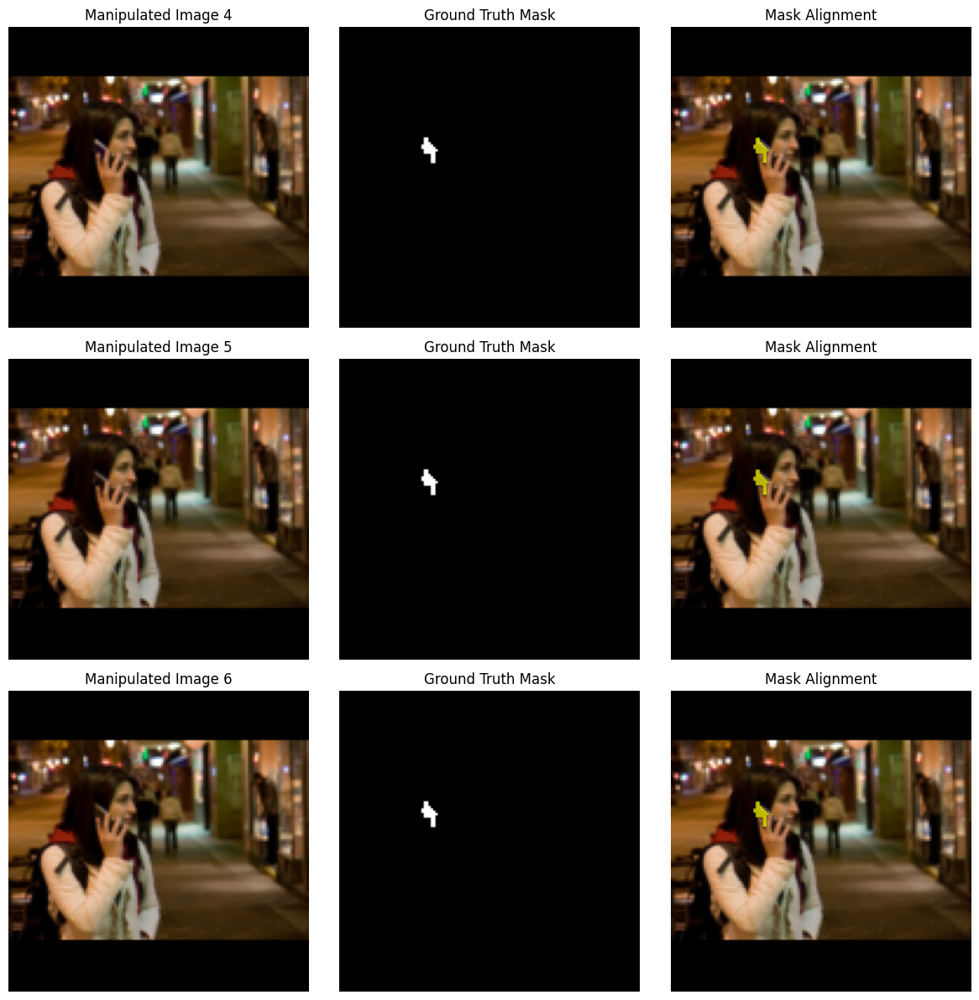

In [43]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row_num, idx in enumerate([4, 5, 6]):
    image = cached_images[idx]
    mask = cached_masks[idx]

    axes[row_num, 0].imshow(image)
    axes[row_num, 0].set_title(f"Manipulated Image {idx}")

    axes[row_num, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row_num, 1].set_title("Ground Truth Mask")

    axes[row_num, 2].imshow(image)
    axes[row_num, 2].imshow(
        np.ma.masked_where(mask == 0, mask),
        cmap="autumn",
        alpha=0.7,
        vmin=0,
        vmax=1
    )
    axes[row_num, 2].set_title("Mask Alignment")

    for ax in axes[row_num]:
        ax.axis("off")

plt.tight_layout()
plt.show()



Dataset index: 4
GT positive pixels: 37
Mean probability inside GT: 0.3136751
Mean probability outside GT: 0.29633608
Overall mean probability: 0.29637527
Probability min/max: 0.22045118 0.47635806

Dataset index: 5
GT positive pixels: 37
Mean probability inside GT: 0.307566
Mean probability outside GT: 0.29629672
Overall mean probability: 0.29632217
Probability min/max: 0.22044395 0.4762927

Dataset index: 6
GT positive pixels: 37
Mean probability inside GT: 0.3089253
Mean probability outside GT: 0.29629463
Overall mean probability: 0.29632315
Probability min/max: 0.22044455 0.47630113


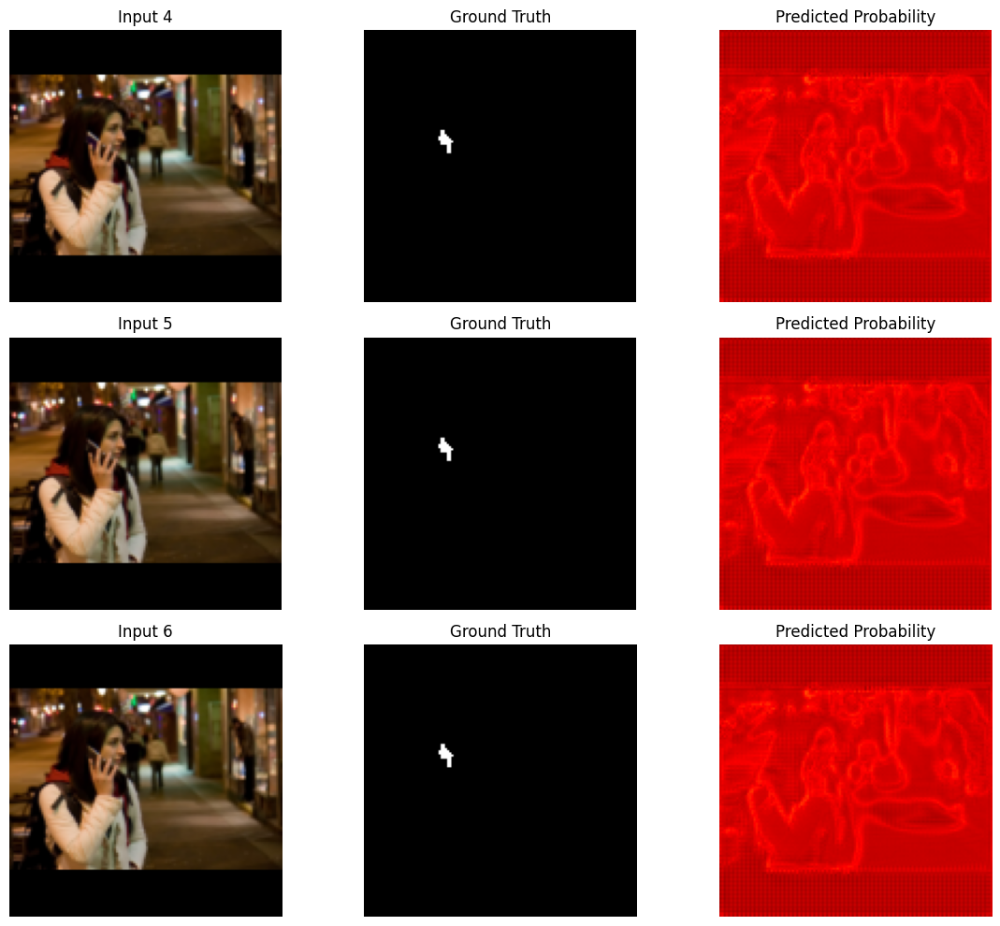

In [44]:

# Analyze predictions for the first three samples
# belonging to source ID 100624

model.eval()

indices = [4, 5, 6]

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

with torch.no_grad():
    for row, idx in enumerate(indices):

        image = torch.tensor(
            np.array(cached_images[idx])
        ).permute(2, 0, 1).float() / 255.0

        mask = np.array(cached_masks[idx])

        image = image.unsqueeze(0).to(device)

        probability = torch.sigmoid(
            model(image)
        ).squeeze().cpu().numpy()

        foreground = mask == 1
        background = mask == 0

        print(f"\nDataset index: {idx}")
        print("GT positive pixels:", foreground.sum())
        print("Mean probability inside GT:",
              probability[foreground].mean())
        print("Mean probability outside GT:",
              probability[background].mean())
        print("Overall mean probability:",
              probability.mean())
        print("Probability min/max:",
              probability.min(), probability.max())

        axes[row, 0].imshow(cached_images[idx])
        axes[row, 0].set_title(f"Input {idx}")

        axes[row, 1].imshow(mask, cmap="gray")
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(
            probability, cmap="hot", vmin=0, vmax=1
        )
        axes[row, 2].set_title("Predicted Probability")

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
plt.show()


In [45]:

# Compare the first validation batch with the cached arrays

batch_images, batch_masks = next(iter(val_loader))

batch_images = batch_images.cpu().numpy()
batch_masks = batch_masks.cpu().numpy()

print("DataLoader image shape:", batch_images.shape)
print("DataLoader mask shape:", batch_masks.shape)

print("\nComparing first 4 validation samples:\n")

for i, idx in enumerate(val_idx[:4]):

    cached_image = np.asarray(cached_images[idx]).astype(np.float32) / 255.0
    cached_mask = np.asarray(cached_masks[idx])

    loader_image = batch_images[i].transpose(1, 2, 0)
    loader_mask = batch_masks[i].squeeze()

    print(f"Sample {i+1} | Dataset index: {idx}")
    print("Cached mask positive pixels:",
          np.count_nonzero(cached_mask))
    print("DataLoader mask positive pixels:",
          np.count_nonzero(loader_mask))

    print("Cached mask shape:", cached_mask.shape)
    print("DataLoader mask shape:", loader_mask.shape)

    print("Image mean absolute difference:",
          np.mean(np.abs(cached_image - loader_image)))

    print("-" * 55)


DataLoader image shape: (4, 3, 256, 256)
DataLoader mask shape: (4, 1, 256, 256)

Comparing first 4 validation samples:

Sample 1 | Dataset index: 4
Cached mask positive pixels: 37
DataLoader mask positive pixels: 146
Cached mask shape: (128, 128)
DataLoader mask shape: (256, 256)


ValueError: operands could not be broadcast together with shapes (128,128,3) (256,256,3) 

In [46]:

print("TRAIN LOADER")
print("Dataset class:", type(train_loader.dataset))
print("Number of samples:", len(train_loader.dataset))
print("Batch size:", train_loader.batch_size)

print("\nVALIDATION LOADER")
print("Dataset class:", type(val_loader.dataset))
print("Number of samples:", len(val_loader.dataset))
print("Batch size:", val_loader.batch_size)

print("\nMODEL")
print("Model:", type(model).__name__)

sample_input, sample_mask = next(iter(train_loader))
print("Training image shape:", sample_input.shape)
print("Training mask shape:", sample_mask.shape)


TRAIN LOADER
Dataset class: <class '__main__.LocalizationDataset'>
Number of samples: 1983
Batch size: 4

VALIDATION LOADER
Dataset class: <class '__main__.LocalizationDataset'>
Number of samples: 265
Batch size: 4

MODEL
Model: SmallUNet
Training image shape: torch.Size([4, 3, 256, 256])
Training mask shape: torch.Size([4, 1, 256, 256])


In [48]:

# Search previously executed notebook cells

keywords = [
    "class LocalizationDataset",
    "class CachedLocalizationDataset",
    "train_loader =",
    "val_loader =",
    "small_unet_128_best.pth",
    "unet_small_128_best.pth",
    "for epoch in range"
]

for keyword in keywords:
    print("\n" + "=" * 70)
    print("SEARCH:", keyword)
    print("=" * 70)

    found = False

    for cell_number, code in enumerate(In):
        if keyword in code:
            found = True
            print(f"\n--- Cell {cell_number} ---")
            print(code[:5000])

    if not found:
        print("Not found in execution history.")



SEARCH: class LocalizationDataset

--- Cell 20 ---
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)


class LocalizationDataset(Dataset):

    def __init__(self, image_paths, mask_paths, indices,
                 image_size=256):

        self.image_paths = image_paths[indices]
        self.mask_paths = mask_paths[indices]
        self.image_size = image_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        # Load image and mask
        image = Image.open(
            self.image_paths[idx]
        ).convert("RGB")

        mask = Image.open(
            self.mask_paths[idx]
        ).convert("L")

        # Preserve aspect ratio
        w, h = image.size

        scale = min(
            self.image_size / w,
            self.image_size / h
        )

        new_w = ro

In [50]:

BATCH_SIZE = 4

train_dataset = LocalizationDataset(
    manipulated_paths, mask_paths, train_idx,
    image_size=256
)

val_dataset = LocalizationDataset(
    manipulated_paths, mask_paths, val_idx,
    image_size=256
)

test_dataset = LocalizationDataset(
    manipulated_paths, mask_paths, test_idx,
    image_size=256
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify
images, masks = next(iter(val_loader))

print("Validation image shape:", images.shape)
print("Validation mask shape:", masks.shape)
print("Validation samples:", len(val_dataset))
print("Training samples:", len(train_dataset))

Validation image shape: torch.Size([4, 3, 256, 256])
Validation mask shape: torch.Size([4, 1, 256, 256])
Validation samples: 265
Training samples: 1983


In [51]:

import torch
import numpy as np

# Load best checkpoint
checkpoint = torch.load(best_model_path, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation Dice:", checkpoint["val_dice"])

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

results = {
    t: {"intersection": 0, "pred": 0, "gt": 0}
    for t in thresholds
}

prob_min = float("inf")
prob_max = float("-inf")
prob_sum = 0.0
total_pixels = 0
total_gt_pixels = 0

with torch.no_grad():
    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        probabilities = torch.sigmoid(model(images))

        prob_min = min(prob_min, probabilities.min().item())
        prob_max = max(prob_max, probabilities.max().item())
        prob_sum += probabilities.sum().item()
        total_pixels += probabilities.numel()

        targets = (masks > 0.5).float()
        total_gt_pixels += targets.sum().item()

        for t in thresholds:
            predictions = (probabilities >= t).float()

            intersection = (predictions * targets).sum().item()
            pred_count = predictions.sum().item()
            gt_count = targets.sum().item()

            results[t]["intersection"] += intersection
            results[t]["pred"] += pred_count
            results[t]["gt"] += gt_count

print("\nProbability statistics")
print("Minimum:", prob_min)
print("Maximum:", prob_max)
print("Mean:", prob_sum / total_pixels)

print("\nGround truth positive pixels:", int(total_gt_pixels))

print("\nGlobal threshold comparison")

for t in thresholds:
    r = results[t]

    dice = (
        2 * r["intersection"] /
        (r["pred"] + r["gt"] + 1e-8)
    )

    iou = (
        r["intersection"] /
        (r["pred"] + r["gt"] - r["intersection"] + 1e-8)
    )

    print(
        f"Threshold {t}: "
        f"Predicted pixels={int(r['pred'])}, "
        f"Dice={dice:.4f}, "
        f"IoU={iou:.4f}"
    )


Checkpoint epoch: 2
Checkpoint validation Dice: 0.021047372539831754

Probability statistics
Minimum: 5.749884803663008e-05
Maximum: 1.0
Mean: 0.2995725105393608

Ground truth positive pixels: 438626

Global threshold comparison
Threshold 0.1: Predicted pixels=17365842, Dice=0.0493, IoU=0.0253
Threshold 0.2: Predicted pixels=17360796, Dice=0.0493, IoU=0.0253
Threshold 0.3: Predicted pixels=6264863, Dice=0.0835, IoU=0.0436
Threshold 0.4: Predicted pixels=491402, Dice=0.1099, IoU=0.0581
Threshold 0.5: Predicted pixels=134654, Dice=0.0578, IoU=0.0298


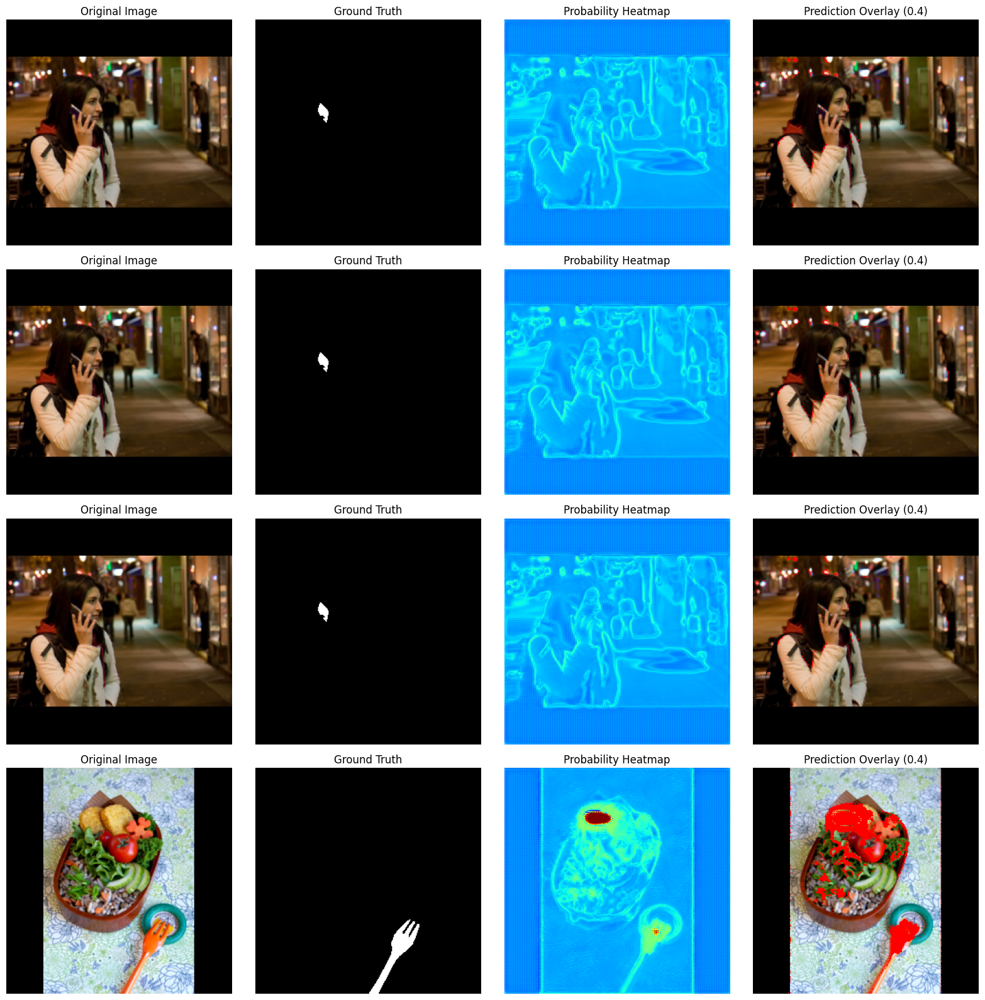

In [52]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Load best checkpoint
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Get one validation batch
images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    probabilities = torch.sigmoid(model(images))

predictions = (probabilities >= 0.4).float()

# Display first 4 samples
fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for i in range(4):

    original = images[i].cpu().permute(1, 2, 0).numpy()
    ground_truth = masks[i, 0].cpu().numpy()
    probability = probabilities[i, 0].cpu().numpy()
    predicted = predictions[i, 0].cpu().numpy()

    overlay = original.copy()
    overlay[predicted > 0] = [1, 0, 0]

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(ground_truth, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(probability, cmap="jet", vmin=0, vmax=1)
    axes[i, 2].set_title("Probability Heatmap")

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Prediction Overlay (0.4)")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


Sample 0
Image dimensions: (1024, 683)
Mask dimensions: (1024, 683)
Positive mask pixels: 2340
Manipulated area: 0.3346%
Dimensions match: True

Sample 3
Image dimensions: (683, 1024)
Mask dimensions: (683, 1024)
Positive mask pixels: 18100
Manipulated area: 2.5880%
Dimensions match: True


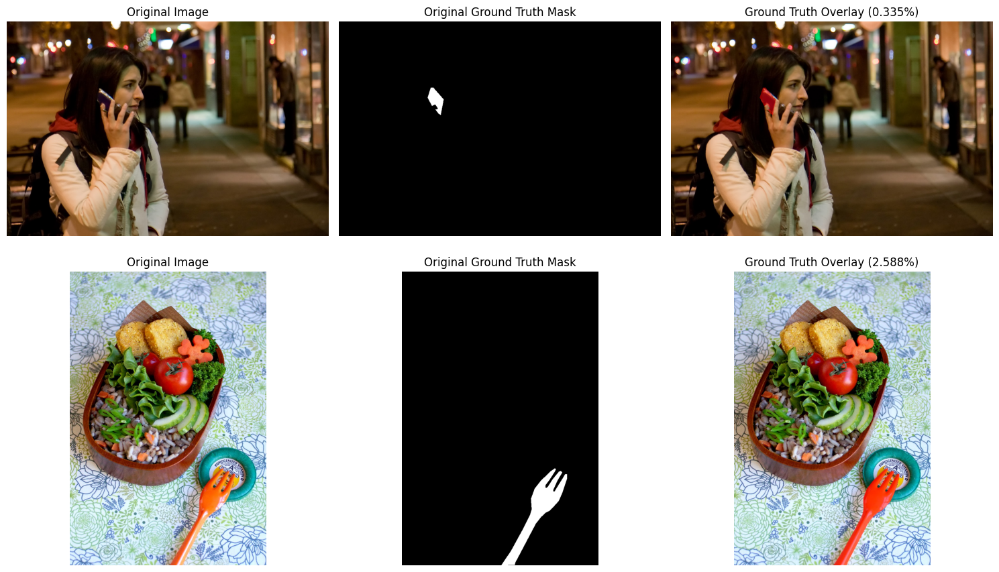

In [53]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Inspect two validation samples
sample_positions = [0, 3]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for row, position in enumerate(sample_positions):

    idx = int(val_idx[position])

    image_path = manipulated_paths[idx]
    mask_path = mask_paths[idx]

    # Load original-resolution files
    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    image_array = np.array(image)
    mask_array = (np.array(mask) > 0)

    # Create overlay
    overlay = image_array.copy()
    overlay[mask_array] = (
        0.5 * overlay[mask_array] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    area_percent = mask_array.sum() / mask_array.size * 100

    axes[row, 0].imshow(image_array)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(mask_array, cmap="gray")
    axes[row, 1].set_title("Original Ground Truth Mask")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        f"Ground Truth Overlay ({area_percent:.3f}%)"
    )

    for ax in axes[row]:
        ax.axis("off")

    print(f"\nSample {position}")
    print("Image dimensions:", image.size)
    print("Mask dimensions:", mask.size)
    print("Positive mask pixels:", mask_array.sum())
    print("Manipulated area:", f"{area_percent:.4f}%")
    print("Dimensions match:", image.size == mask.size)

plt.tight_layout()
plt.show()

In [54]:
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

IMAGE_SIZE = 256

def get_resized_mask_stats(mask_path):

    mask = Image.open(mask_path).convert("L")

    w, h = mask.size

    scale = min(IMAGE_SIZE / w, IMAGE_SIZE / h)

    new_w = round(w * scale)
    new_h = round(h * scale)

    mask = mask.resize(
        (new_w, new_h),
        Image.Resampling.NEAREST
    )

    canvas = Image.new(
        "L",
        (IMAGE_SIZE, IMAGE_SIZE),
        0
    )

    x_offset = (IMAGE_SIZE - new_w) // 2
    y_offset = (IMAGE_SIZE - new_h) // 2

    canvas.paste(mask, (x_offset, y_offset))

    mask_array = np.array(canvas) > 0

    return mask_array.sum()


def analyze_split(indices, split_name):

    percentages = []
    positive_pixels = []

    for idx in tqdm(indices, desc=split_name):

        count = get_resized_mask_stats(mask_paths[int(idx)])

        positive_pixels.append(count)
        percentages.append(count / (IMAGE_SIZE * IMAGE_SIZE) * 100)

    percentages = np.array(percentages)
    positive_pixels = np.array(positive_pixels)

    print(f"\n{split_name} statistics")
    print("----------------------------")
    print("Images:", len(indices))
    print("Zero-mask images:", np.sum(positive_pixels == 0))
    print("Mean manipulated area:", round(percentages.mean(), 4), "%")
    print("Median manipulated area:", round(np.median(percentages), 4), "%")
    print("Minimum manipulated area:", round(percentages.min(), 4), "%")
    print("Maximum manipulated area:", round(percentages.max(), 4), "%")
    print("Total positive pixels:", positive_pixels.sum())

    return percentages, positive_pixels


train_percentages, train_pixels = analyze_split(
    train_idx, "Training"
)

val_percentages, val_pixels = analyze_split(
    val_idx, "Validation"
)

Training:   0%|          | 0/1983 [00:00<?, ?it/s]


Training statistics
----------------------------
Images: 1983
Zero-mask images: 0
Mean manipulated area: 2.9481 %
Median manipulated area: 1.506 %
Minimum manipulated area: 0.0732 %
Maximum manipulated area: 28.7247 %
Total positive pixels: 3831310


Validation:   0%|          | 0/265 [00:00<?, ?it/s]


Validation statistics
----------------------------
Images: 265
Zero-mask images: 0
Mean manipulated area: 2.5256 %
Median manipulated area: 1.4404 %
Minimum manipulated area: 0.1205 %
Maximum manipulated area: 16.4444 %
Total positive pixels: 438630


In [55]:
import torch
import torch.nn as nn

class WeightedBCEDiceLoss(nn.Module):

    def __init__(self, pos_weight=10.0):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor([pos_weight])
        )

    def forward(self, logits, targets):

        # Weighted BCE
        bce_loss = self.bce(
            logits,
            targets
        )

        # Dice loss
        probabilities = torch.sigmoid(logits)

        intersection = (
            probabilities * targets
        ).sum(dim=(1, 2, 3))

        denominator = (
            probabilities.sum(dim=(1, 2, 3)) +
            targets.sum(dim=(1, 2, 3))
        )

        dice_score = (
            2 * intersection + 1
        ) / (
            denominator + 1
        )

        dice_loss = 1 - dice_score.mean()

        return bce_loss + dice_loss


criterion = WeightedBCEDiceLoss(pos_weight=10.0).to(device)

print("Weighted BCE + Dice Loss initialized!")
print("Positive pixel weight:", 10.0)

Weighted BCE + Dice Loss initialized!
Positive pixel weight: 10.0


In [56]:
# Initialize a fresh model
model = SmallUNet().to(device)

# New optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

# Separate checkpoint
best_model_path = os.path.join(
    LOC_MODELS_DIR,
    "unet_weighted_bce_dice_256_best.pth"
)

print("Fresh model initialized.")
print("Device:", device)
print("Checkpoint:", best_model_path)

Fresh model initialized.
Device: cuda
Checkpoint: /content/drive/MyDrive/AI_Image_Project/saved_models/localization/unet_weighted_bce_dice_256_best.pth


In [57]:

from tqdm.auto import tqdm
import torch
import numpy as np
import os

EPOCHS = 3
THRESHOLD = 0.4

best_val_dice = 0.0

for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()
    train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} - Training"
    )

    for images, masks in train_bar:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = train_loss / len(train_loader)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss = 0.0
    intersection = 0.0
    pred_pixels = 0.0
    gt_pixels = 0.0

    with torch.no_grad():

        for images, masks in tqdm(
            val_loader,
            desc="Validation"
        ):

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            loss = criterion(logits, masks)

            val_loss += loss.item()

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= THRESHOLD).float()
            targets = (masks >= 0.5).float()

            intersection += (predictions * targets).sum().item()
            pred_pixels += predictions.sum().item()
            gt_pixels += targets.sum().item()

    avg_val_loss = val_loss / len(val_loader)

    val_dice = (
        2 * intersection + 1e-7
    ) / (
        pred_pixels + gt_pixels + 1e-7
    )

    val_iou = (
        intersection + 1e-7
    ) / (
        pred_pixels + gt_pixels - intersection + 1e-7
    )

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Training Loss:   {avg_train_loss:.4f}")
    print(f"Validation Loss: {avg_val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Validation IoU:  {val_iou:.4f}")

    # -------------------------
    # SAVE BEST CHECKPOINT
    # -------------------------
    if val_dice > best_val_dice:

        best_val_dice = val_dice

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": val_dice,
            "val_iou": val_iou,
            "threshold": THRESHOLD
        }, best_model_path)

        print("Best weighted-loss model saved!")

print("\nTraining completed.")
print("Best validation Dice:", best_val_dice)
print("Checkpoint:", best_model_path)


Epoch 1/3 - Training:   0%|          | 0/496 [00:00<?, ?it/s]

Validation:   0%|          | 0/67 [00:00<?, ?it/s]


Epoch 1/3
Training Loss:   1.6707
Validation Loss: 1.5833
Validation Dice: 0.0976
Validation IoU:  0.0513
Best weighted-loss model saved!


Epoch 2/3 - Training:   0%|          | 0/496 [00:00<?, ?it/s]

Validation:   0%|          | 0/67 [00:00<?, ?it/s]


Epoch 2/3
Training Loss:   1.5535
Validation Loss: 1.5462
Validation Dice: 0.1202
Validation IoU:  0.0639
Best weighted-loss model saved!


Epoch 3/3 - Training:   0%|          | 0/496 [00:00<?, ?it/s]

Validation:   0%|          | 0/67 [00:00<?, ?it/s]


Epoch 3/3
Training Loss:   1.4927
Validation Loss: 1.4837
Validation Dice: 0.1273
Validation IoU:  0.0680
Best weighted-loss model saved!

Training completed.
Best validation Dice: 0.1272746523286539
Checkpoint: /content/drive/MyDrive/AI_Image_Project/saved_models/localization/unet_weighted_bce_dice_256_best.pth


In [58]:

import torch
import numpy as np

# Load best weighted model
checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Saved validation Dice:", checkpoint["val_dice"])

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = {
    t: {"intersection": 0, "pred": 0, "gt": 0}
    for t in thresholds
}

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        probabilities = torch.sigmoid(model(images))
        targets = (masks >= 0.5).float()

        for t in thresholds:

            predictions = (probabilities >= t).float()

            results[t]["intersection"] += (
                predictions * targets
            ).sum().item()

            results[t]["pred"] += predictions.sum().item()
            results[t]["gt"] += targets.sum().item()


print("\nGLOBAL VALIDATION RESULTS")
print("-" * 65)

for t in thresholds:

    intersection = results[t]["intersection"]
    pred = results[t]["pred"]
    gt = results[t]["gt"]

    dice = (2 * intersection + 1e-7) / (
        pred + gt + 1e-7
    )

    iou = (intersection + 1e-7) / (
        pred + gt - intersection + 1e-7
    )

    print(
        f"Threshold: {t:.1f} | "
        f"Predicted pixels: {int(pred):,} | "
        f"Dice: {dice:.4f} | "
        f"IoU: {iou:.4f}"
    )


Best checkpoint epoch: 3
Saved validation Dice: 0.1272746523286539

GLOBAL VALIDATION RESULTS
-----------------------------------------------------------------
Threshold: 0.1 | Predicted pixels: 16,218,512 | Dice: 0.0524 | IoU: 0.0269
Threshold: 0.2 | Predicted pixels: 7,158,387 | Dice: 0.0940 | IoU: 0.0493
Threshold: 0.3 | Predicted pixels: 4,349,405 | Dice: 0.1150 | IoU: 0.0610
Threshold: 0.4 | Predicted pixels: 2,819,839 | Dice: 0.1273 | IoU: 0.0680
Threshold: 0.5 | Predicted pixels: 1,698,752 | Dice: 0.1336 | IoU: 0.0716
Threshold: 0.6 | Predicted pixels: 702,017 | Dice: 0.1228 | IoU: 0.0654
Threshold: 0.7 | Predicted pixels: 215,206 | Dice: 0.0791 | IoU: 0.0412


Image 1: GT pixels=146, Predicted pixels=1993
Image 2: GT pixels=146, Predicted pixels=1968
Image 3: GT pixels=146, Predicted pixels=1962
Image 4: GT pixels=1128, Predicted pixels=8700


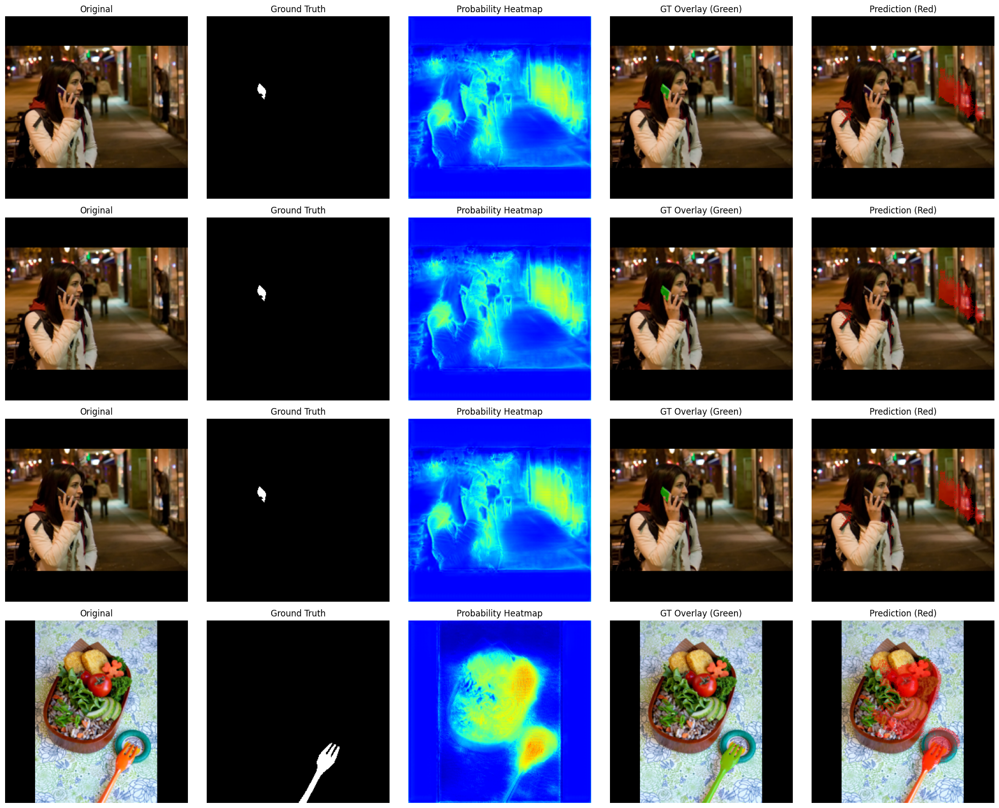

In [59]:

import matplotlib.pyplot as plt
import numpy as np
import torch

# Model is already loaded with the best weighted checkpoint
model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    probabilities = torch.sigmoid(model(images))

predictions = (probabilities >= 0.5).float()

fig, axes = plt.subplots(4, 5, figsize=(20, 16))

for i in range(4):

    original = images[i].cpu().permute(1, 2, 0).numpy()
    gt = masks[i, 0].cpu().numpy()
    prob = probabilities[i, 0].cpu().numpy()
    pred = predictions[i, 0].cpu().numpy()

    # Ground truth overlay
    gt_overlay = original.copy()
    gt_overlay[gt > 0.5] = (
        0.5 * gt_overlay[gt > 0.5] +
        0.5 * np.array([0, 1, 0])
    )

    # Prediction overlay
    pred_overlay = original.copy()
    pred_overlay[pred > 0] = (
        0.5 * pred_overlay[pred > 0] +
        0.5 * np.array([1, 0, 0])
    )

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(gt, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(prob, cmap="jet", vmin=0, vmax=1)
    axes[i, 2].set_title("Probability Heatmap")

    axes[i, 3].imshow(gt_overlay)
    axes[i, 3].set_title("GT Overlay (Green)")

    axes[i, 4].imshow(pred_overlay)
    axes[i, 4].set_title("Prediction (Red)")

    print(
        f"Image {i+1}: "
        f"GT pixels={int(gt.sum())}, "
        f"Predicted pixels={int(pred.sum())}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()



In [1]:

import torch

model.eval()

def evaluate_segmentation(loader, split_name, threshold=0.5):

    intersection = 0
    predicted_pixels = 0
    ground_truth_pixels = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            probabilities = torch.sigmoid(model(images))

            predictions = (probabilities >= threshold).float()
            targets = (masks >= 0.5).float()

            intersection += (predictions * targets).sum().item()
            predicted_pixels += predictions.sum().item()
            ground_truth_pixels += targets.sum().item()

    dice = (
        2 * intersection + 1e-7
    ) / (
        predicted_pixels + ground_truth_pixels + 1e-7
    )

    iou = (
        intersection + 1e-7
    ) / (
        predicted_pixels + ground_truth_pixels - intersection + 1e-7
    )

    precision = (
        intersection + 1e-7
    ) / (predicted_pixels + 1e-7)

    recall = (
        intersection + 1e-7
    ) / (ground_truth_pixels + 1e-7)

    print(f"\n{split_name} Results")
    print("-" * 40)
    print(f"Dice:               {dice:.4f}")
    print(f"IoU:                {iou:.4f}")
    print(f"Precision:          {precision:.4f}")
    print(f"Recall:             {recall:.4f}")
    print(f"Predicted pixels:   {int(predicted_pixels):,}")
    print(f"Ground truth pixels:{int(ground_truth_pixels):,}")

    return dice, iou


train_metrics = evaluate_segmentation(
    train_loader, "TRAINING", threshold=0.5
)

val_metrics = evaluate_segmentation(
    val_loader, "VALIDATION", threshold=0.5
)


NameError: name 'model' is not defined